# 数据清洗与量化编码

## 目标
将原始问卷的 13 道题映射为可分析的数值变量，完成数据清洗与编码。

## 输入
- `data/raw/survey_raw.xlsx`

## 输出
- `data/processed/survey_cleaned.xlsx`

## 对应方法
- 文本清洗、变量量化、多选题拆分

In [1]:
# 环境准备与依赖导入
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import re
from pathlib import Path

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

# notebook 位于 notebooks/ 目录，数据与产物在仓库根目录下
RAW_PATH = Path("../data/raw/survey_raw.xlsx")
PROCESSED_PATH = Path("../data/processed/survey_cleaned.xlsx")
CHART_DIR = Path("../results/charts")

In [2]:
# 数据源读取
excel_path = RAW_PATH

df_raw = pd.read_excel(excel_path, sheet_name="Sheet1")
print("文件：", excel_path)
print("形状：", df_raw.shape)
for c in df_raw.columns:
    print(" -", c)

文件： ..\data\raw\survey_raw.xlsx
形状： (100, 13)
 - 1、你的年龄是？
 - 2、 在扫码、免密等“无感支付”很方便的情况下，你是否有过冲动之下购买原本没计划买的东西？
 - 3、 你平时在哪些日常生活消费场景中最容易产生“非计划性开销”？（可多选）
 - 4、 面对单价500-5000元的上述商品，如果能使用“0利息，支持3-12期”的小额分期，你会更倾向于购买吗？
 - 5、针对无感支付导致的冲动消费，支付后提供“24小时无条件取消”，能打消你的顾虑吗？
 - 6、在分期管理工具中，你最看重以下哪一项？
 - 7、你每月生活费大约是：
 - 8、你每月生活费中可自由支配的比例大约是：
 - 9、你之前是否尝试过分期付款或信用消费？
 - 10、如果这个月生活费不够，你通常会：
 - 11、你能接受“单笔≤5000元、累计≤10000元、只能购票不能转账取现”吗？
 - 12、你是否有演出购票、旅行、二手购物、拼团购物的分期消费需求？
 - 13、官方渠道推荐的金融产品，你比电话推销更信任吗？（更信任/差不多/都怀疑）


In [3]:
# 列名映射：13 道题 -> 分析用短名
import re

def find_col(prefix):
    for c in df_raw.columns:
        c_clean = str(c).strip().replace("\xa0", " ").replace("\u3000", " ")
        if c_clean.startswith(prefix):
            return c
    return None

col_map = {
    "age": "1、",
    "impulse": "2、",
    "scene": "3、",
    "demand_4": "4、",
    "cooling": "5、",
    "focus": "6、",
    "living": "7、",
    "disposable": "8、",
    "installment_use": "9、",
    "shortage": "10、",
    "limit_accept": "11、",
    "demand": "12、",
    "trust": "13、",
}

rename_map = {}
for new_name, prefix in col_map.items():
    old = find_col(prefix)
    if old:
        rename_map[old] = new_name
    else:
        print("没找到：", prefix)

df = df_raw.rename(columns=rename_map)
df = df[list(col_map.keys())].copy()
print("列名：", df.columns.tolist())

列名： ['age', 'impulse', 'scene', 'demand_4', 'cooling', 'focus', 'living', 'disposable', 'installment_use', 'shortage', 'limit_accept', 'demand', 'trust']


In [4]:
# 文本清洗：不可见字符与多余空白
def clean_text(s):
    if not isinstance(s, str):
        return s
    s = s.replace("\xa0", " ").replace("\u3000", " ").replace("\u200b", "")
    s = re.sub(r"\s+", " ", s)
    return s.strip()

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].map(clean_text)

print("清洗完成")
print(df["focus"].unique())

清洗完成
<StringArray>
['智能消费提醒与预算红线预警', '场景覆盖多', '绝对零利息、没有隐形套路', '支付后有24小时冷静期防冲动']
Length: 4, dtype: str


In [5]:
# 变量量化编码 + 多选题拆分
living_map = {
    "1000–1500元": 1250,
    "1500–2000元": 1750,
    "2000–3000元": 2500,
    "3000元以上": 3500,
}
disposable_map = {
    "10%以下": 0.05,
    "10%–20%": 0.15,
    "20%–30%": 0.25,
    "30%以上": 0.35,
}
impulse_rank = {
    "几乎没有，消费很理性": 1,
    "偶尔会有": 2,
    "经常有，经常不知不觉花超预算": 3,
}
demand_rank = {
    "完全没有": 1,
    "几乎没有": 2,
    "偶尔有": 3,
    "经常有": 4,
}
demand4_rank = {
    "不会，不需要分期": 1,
    "可能会": 2,
    "会，极大降低了购买门槛": 3,
}
cooling_rank = {
    "不需要": 1,
    "一般/无所谓": 2,
    "能，提供了一层很好的后悔与冷静机制": 3,
}
trust_rank = {
    "都怀疑": 1,
    "差不多": 2,
    "更信任": 3,
}
installment_rank = {
    "从没用过": 1,
    "用过，但已经关掉/不再用了": 2,
    "用过几次，基本按时还": 3,
}
shortage_rank = {
    "借新的钱来还旧的": 1,
    "找朋友或家人借": 2,
    "减少开支撑过去": 3,
}
limit_rank = {
    "不能接受": 1,
    "一般": 2,
    "能接受": 3,
}

df["living_num"] = df["living"].map(living_map)
df["disposable_num"] = df["disposable"].map(disposable_map)
df["impulse_rank"] = df["impulse"].map(impulse_rank)
df["demand_rank"] = df["demand"].map(demand_rank)
df["demand4_rank"] = df["demand_4"].map(demand4_rank)
df["cooling_rank"] = df["cooling"].map(cooling_rank)
df["trust_rank"] = df["trust"].map(trust_rank)
df["installment_rank"] = df["installment_use"].map(installment_rank)
df["shortage_rank"] = df["shortage"].map(shortage_rank)
df["limit_rank"] = df["limit_accept"].map(limit_rank)

# 多选题第3题
scene_options = ["文娱票务","潮玩周边","户外与娱乐用品","假期旅游","数码电子","服饰美妆","二手交易"]
for opt in scene_options:
    df[f"scene_{opt}"] = df["scene"].fillna("").str.contains(opt).astype(int)

print("映射完成，检查缺失：")
print(df[["living_num","disposable_num","impulse_rank","demand4_rank","trust_rank"]].isna().sum())

映射完成，检查缺失：
living_num        0
disposable_num    0
impulse_rank      0
demand4_rank      0
trust_rank        0
dtype: int64


In [6]:
# 导出清洗后的数据
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
df.to_excel(processed_dir / "survey_cleaned.xlsx", index=False)
print(f"已导出：{processed_dir / 'survey_cleaned.xlsx'}")

已导出：..\data\processed\survey_cleaned.xlsx


## 附：数据清洗流程图

问卷从回收到进入分析的全过程：回收 127 份 → 剔除无效样本 → 随机抽样至 100 份。

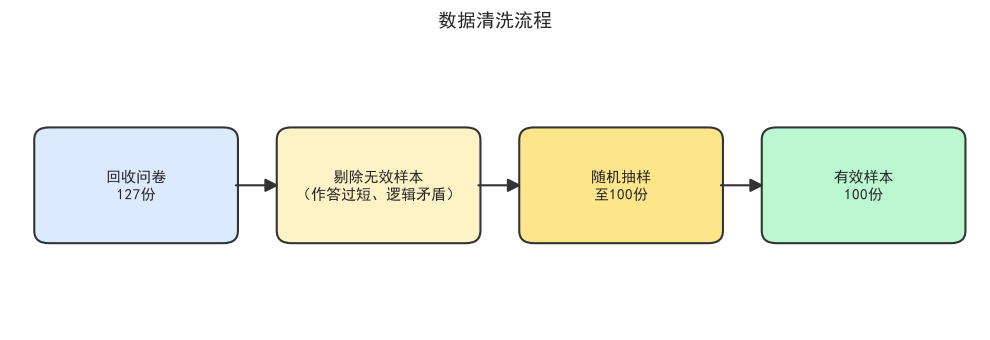

已保存： ..\results\charts\data_cleaning_flow.png


In [7]:
# 数据清洗流程图
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 3.5)
ax.axis("off")

# 四个框：内容、x 坐标、颜色
boxes = [
    ("回收问卷\n127份", 1.3, "#dbeafe"),
    ("剔除无效样本\n（作答过短、逻辑矛盾）", 3.8, "#fef3c7"),
    ("随机抽样\n至100份", 6.3, "#fde68a"),
    ("有效样本\n100份", 8.8, "#bbf7d0"),
]

box_w, box_h = 1.9, 1.2
y_center = 1.75

for text, x, color in boxes:
    box = FancyBboxPatch(
        (x - box_w/2, y_center - box_h/2), box_w, box_h,
        boxstyle="round,pad=0.1,rounding_size=0.15",
        linewidth=1.5, edgecolor="#333333", facecolor=color
    )
    ax.add_patch(box)
    ax.text(x, y_center, text, ha="center", va="center", fontsize=11)

# 箭头
for i in range(len(boxes) - 1):
    x_start = boxes[i][1] + box_w/2
    x_end = boxes[i+1][1] - box_w/2
    arrow = FancyArrowPatch(
        (x_start + 0.05, y_center), (x_end - 0.05, y_center),
        arrowstyle="-|>", mutation_scale=20,
        linewidth=1.5, color="#333333"
    )
    ax.add_patch(arrow)

ax.set_title("数据清洗流程", fontsize=14, pad=10)

CHART_DIR.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(CHART_DIR / "data_cleaning_flow.png", dpi=200, bbox_inches="tight")
plt.show()
print("已保存：", CHART_DIR / "data_cleaning_flow.png")